In [1]:
import dotenv
from langchain_naver import ChatClovaX
import httpx, uuid, os, json

dotenv.load_dotenv()

clova = ChatClovaX(
    api_key=os.getenv('NCP_CLOVASTUDIO_API_KEY'),
    model="HCX-005",
    temperature=0.2,
    max_tokens=None,
    timeout=None,
    # max_retries,
    # repeat_penalt,
    # repetition_penalty,
    # stop,
    # seed,
    # top_k,
    # top_p,
)

# Function Calling 호출 API
API_KEY = os.getenv('NCP_CLOVASTUDIO_API_KEY')
REQUEST_ID = f"req-{uuid.uuid4()}"

url = "https://clovastudio.stream.ntruss.com/testapp/v3/chat-completions/HCX-005"
headers = {
    "Authorization": f"Bearer {API_KEY}",
    "X-NCP-CLOVASTUDIO-REQUEST-ID": REQUEST_ID,
    "Content-Type": "application/json"
}

In [8]:
from task1_tools import *
from typing import Dict, Any

task1_functions = [
    {
        "name": "get_info_stock",
        "description": "주어진 날짜(date)에 대해 특정 종목(stock_name)의 pbr,per,시가(Open), 고가(High), 저가(Low), 종가(Close) 또는 거래량(Volume) 중 하나(field)에 해당하는 값을 반환합니다. field 값은 한글(시가·고가·저가·종가·거래량)이나 영문(open·high·low·close·volume)으로 지정할 수 있으며, 반드시 그중 하나만 선택해야 합니다.",
        "parameters": {
            "type": "object",
            "properties": {
                "stock_name": {"type": "string"},
                "date": {"type": "string", "format": "date"},
                "field": {"type": "string", "enum": ["open", "high", "low", "close", "volume","pbr","per,","시가", "고가", "저가", "종가", "거래량"]}
            },
            "required": ["stock_name", "date", "field"]
        }
    },
    {
        "name": "get_volume_range",
        "description": "기간(start~end) 거래량 조회: 시작~종료 날짜 구간의 거래량을 'aggregate' 방식대로 반환( 'daily' = 일별 배열, 'sum' = 기간 총합 )."
                        "'전날 대비' 같은 **기간 비교** 질문에만 사용.",
        "parameters": {
            "type": "object",
            "properties": {
                "stock_name": {"type": "string"},
                "start_date": {"type": "string", "format": "date"},
                "end_date":   {"type": "string", "format": "date"},
                "aggregate":  {
                    "type": "string",
                    "enum": ["sum", "daily"],
                    "default": "sum"
                }
            },
            "required": ["stock_name", "start_date", "end_date"]
        }
    },
    {
        "name": "get_change_pct",
        "description": "두 날짜(또는 전일 대비) 주가 변동률",
        "parameters": {
            "type": "object",
            "properties": {
                "stock_name": {"type": "string"},
                "date_from": {"type": "string", "format": "date"},
                "date_to": {"type": "string", "format": "date"}
            },
            "required": ["stock_name", "date_from"]
        }
    },
    {
        "name": "get_top_volume",
        "description": "거래량 상위 N종목",
        "parameters": {
            "type": "object",
            "properties": {
                "date": {"type": "string", "format": "date"},
                "top_n": {"type": "integer", "default": 10}
            },
            "required": ["date"]
        }
    },
    {
        "name": "get_top_gain",
        "description": "상승률 상위 N종목",
        "parameters": {
            "type": "object",
            "properties": {
                "date": {"type": "string", "format": "date"},
                "top_n": {"type": "integer", "default": 10}
            },
            "required": ["date"]
        }
    },
    {
        "name": "get_top_drop",
        "description": "하락률 상위 N종목",
        "parameters": {
            "type": "object",
            "properties": {
                "date": {"type": "string", "format": "date"},
                "top_n": {"type": "integer", "default": 10}
            },
            "required": ["date"]
        }
    },
]

task1_py_funcs: Dict[str, Any] = {
    "get_info_stock": get_info_stock,
    "get_volume_range": get_volume_range,
    "get_change_pct": get_change_pct,
    "get_top_volume": get_top_volume,
    "get_top_gain": get_top_gain,
    "get_top_drop": get_top_drop
}

In [9]:
from typing import Annotated, List, TypedDict, Dict
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import AIMessage
from langgraph.graph import StateGraph, START, END
import os

class ChatbotState(TypedDict):
    question: Annotated[str, "Question"]  
    decision_task: Annotated[str, "Decision_task"]
    tools: Annotated[List, "Tools"]
    tools_response: Annotated[str, "Tools_Response"]
    answer: Annotated[str, "Final_Answer"]  
    messages: Annotated[List, add_messages] 

memory = MemorySaver()

In [10]:
TASK_ROUTER_PROMPT = """
당신은 주식 정보 시스템을 위한 작업 분류 도우미입니다.

당신의 임무는 사용자의 질문을 다음 네 가지 작업(Task) 중 하나로 분류하는 것입니다:

- Task 1: 단순 조회
- Task 2: 조건 검색
- Task 3: 시그널 감지
- Task 4: 모호한 의미 해석

아래 정의를 참고하여 분류하세요:

Task 1 (단순 조회):
  - "OO의 00 날짜 상승률은?"
  - "OO일에 거래량 기준 상위 10개 종목은?"

Task 2 (조건 검색):
  - "전날 대비 거래량이 NN% 이상 증가한 종목"

Task 3 (시그널 감지):
  - "50일 이동평균선을 돌파한 종목"

Task 4 (모호한 의미 해석):
  - "최근 많이 오른 주식"
  - "고점 대비 가장 많이 떨어진 종목"

답변은 반드시 Task1·Task2·Task3·Task4 중 하나만 출력.
<answer>
"Task1" | "Task2" | "Task3" | "Task4"
</answer>

사용자 질문: "{question}"

"""

TOOLS_PROMPT = (
        "너는 주식 정보용 Tool Router다.\n"
        "아래 제공된 함수 중 **정확히 하나**만 선택해서 호출해야 한다.\n"
        "함수 이름이 2개 이상 들어가거나, 목록에 없는 함수명을 생성하면 안 된다."
    )


In [11]:
from langchain.schema import SystemMessage, HumanMessage, AIMessage
import json, inspect, asyncio, requests

async def decision_task(state: ChatbotState):
    user_query = state["question"]
    
    prompt = TASK_ROUTER_PROMPT.format(question=user_query)
    messages = [("system",prompt)]

    llm_response = await clova.ainvoke(messages)

    response = llm_response.content

    # task: str | None = None        # 미리 초기화

    if response:
        response = re.sub(r"\s+", "", response)   # 'Task 1' → 'Task1'
        response = response.capitalize()  

    # # ① <answer> 태그 뒤 TaskX 찾기
    # m = re.search(
    #     r"<answer>\s*['\"`({\[]?\s*(Task\d+)",
    #     response,
    #     flags=re.IGNORECASE,
    # )
    # if m:
    #     task = m.group(1)

    # # ② 태그가 없어도 문장에 TaskX 가 있으면
    # if task is None:
    #     m2 = re.search(r"\bTask\d+\b", response)
    #     if m2:
    #         task = m2.group(0)

    # # ③ 여전히 None 이면 LLM 원문 저장 (디버깅/재분류용)
    # if task is None:
    #     task = response.strip()

    return ChatbotState(decision_task=response)


async def task1_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"system","content": TOOLS_PROMPT},
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    tool_calls = result['result']['message']['toolCalls']

    for call in tool_calls:
        fn_name = call["function"]["name"]
        args    = call["function"]["arguments"]     # dict 또는 JSON 문자열
        if isinstance(args, str):
            args = json.loads(args)

        py_func = task1_py_funcs.get(fn_name)
        if py_func is None:
            raise ValueError(f"Unsupported function: {fn_name}")

        # 동기/비동기 모두 지원
        if asyncio.iscoroutinefunction(py_func):
            out = await py_func(**args)
        else:
            out = await asyncio.to_thread(py_func, **args)

    return ChatbotState(tools=result,
                        tools_response=out)

async def task2_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)

async def task3_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)

async def task4_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)


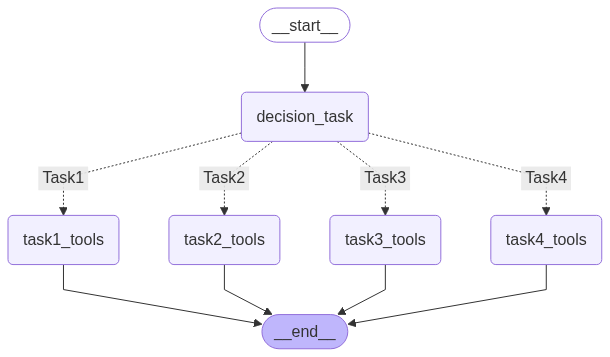

In [12]:
def route_tools(state: ChatbotState):
    return state["decision_task"]

builder = StateGraph(ChatbotState)

builder.add_node("decision_task", decision_task)
builder.add_node("task1_tools", task1_tools)
builder.add_node("task2_tools", task2_tools)
builder.add_node("task3_tools", task3_tools)
builder.add_node("task4_tools", task4_tools)

builder.add_edge(START, "decision_task")
builder.add_conditional_edges(
    "decision_task",
    route_tools,
    {"Task1": "task1_tools",
    "Task2": "task2_tools",
    "Task3": "task3_tools",
    "Task4": "task4_tools",}
    )
builder.add_edge("task1_tools", END)
builder.add_edge("task2_tools", END)
builder.add_edge("task3_tools", END)
builder.add_edge("task4_tools", END)

builder.compile(checkpointer=memory)

In [13]:
from langchain_core.runnables import RunnableConfig

config = RunnableConfig(configurable={"thread_id": 1})

question = "삼성전자의 PBR은?"

graph = builder.compile(checkpointer=memory)

initial_state = {
    "question": question,
    "decision_task":"",
    "tools": [],
    "tools_query" : [],
    "answer": "",
    "messages": [],
}

events = []
async for event in graph.astream(initial_state,config=config):
    print(event)
    events.append(event)

{'decision_task': {'decision_task': 'Task1'}}
{'task1_tools': {'tools': {'status': {'code': '20000', 'message': 'OK'}, 'result': {'message': {'role': 'assistant', 'content': '', 'toolCalls': [{'id': 'call_vVV5ljaQgFrVsNJ1mJRItK7b', 'type': 'function', 'function': {'name': 'get_info_stock', 'arguments': {'stock_name': '삼성전자', 'date': '2025-07-06', 'field': 'pbr'}}}]}, 'finishReason': 'tool_calls', 'created': 1751767152, 'seed': 409933843, 'usage': {'promptTokens': 61, 'completionTokens': 50, 'totalTokens': 111}}}, 'tools_response': '❌ 삼성전자의 PBR 정보를 가져올 수 없습니다.'}}
